# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

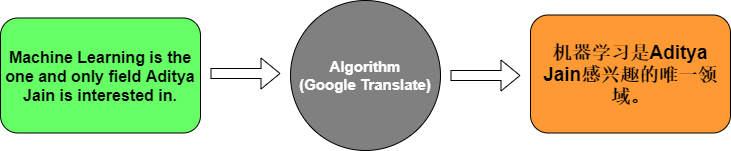

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. It converts each word index into a numerical vector that the model can use to learn word meanings and relationships.
2. It reads the English sentence and learns its important information to help the model understand the sentence.
3. It uses the information learned by the encoder to generate the translated sentence in French.
4. Softmax converts the model's outputs into probabilities for each possible word, allowing the model to predict the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [2]:
%pip install -q "protobuf>=5.28,<6" kagglehub tensorflow pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.


In [2]:
# 1. Import libraries
import kagglehub
import pandas as pd
import numpy as np
import tensorflow as tf
import os
import zipfile
import re

from pathlib import Path
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("KaggleHub ready")

TensorFlow: 2.20.0
KaggleHub ready


In [3]:
# 2. Load the provided Kaggle dataset
path = kagglehub.dataset_download(
    "devicharith/language-translation-englishfrench"
)

print("Dataset location:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Dataset location: C:\Users\Zalkh\.cache\kagglehub\datasets\devicharith\language-translation-englishfrench\versions\2
C:\Users\Zalkh\.cache\kagglehub\datasets\devicharith\language-translation-englishfrench\versions\2\eng_-french.csv


In [4]:
# 3. Extract and read the dataset
dataset_path = Path(path)

# Extract ZIP files, if present
for zip_path in dataset_path.rglob("*.zip"):
    extract_folder = zip_path.parent / zip_path.stem
    extract_folder.mkdir(exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_folder)

# Find the English-French data file
data_files = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in [".csv", ".txt", ".tsv"]
]

print("Available data files:", data_files)

if not data_files:
    raise FileNotFoundError("No CSV or text dataset found.")

# Prefer the English-French sentence file
data_file = next(
    (p for p in data_files if "fra" in p.name.lower()
     or "eng" in p.name.lower()),
    data_files[0]
)

print("Reading:", data_file)

# Read as a tab-separated or CSV file
if data_file.suffix.lower() in [".txt", ".tsv"]:
    df = pd.read_csv(
        data_file,
        sep="\t",
        header=None,
        encoding="utf-8",
        on_bad_lines="skip"
    )
else:
    df = pd.read_csv(data_file)

    if df.shape[1] < 2:
        df = pd.read_csv(data_file, header=None)

# Identify columns
column_names = {
    str(c).strip().lower(): c for c in df.columns
}

english_col = column_names.get("english")
french_col = column_names.get("french")

if english_col is not None and french_col is not None:
    df = df[[english_col, french_col]].copy()
else:
    df = df.iloc[:, :2].copy()

df.columns = ["English", "French"]

df = df.dropna().drop_duplicates()

print("Total sentence pairs:", len(df))
print(df.head())

Available data files: [WindowsPath('C:/Users/Zalkh/.cache/kagglehub/datasets/devicharith/language-translation-englishfrench/versions/2/eng_-french.csv')]
Reading: C:\Users\Zalkh\.cache\kagglehub\datasets\devicharith\language-translation-englishfrench\versions\2\eng_-french.csv
Total sentence pairs: 175621
  English      French
0     Hi.      Salut!
1    Run!     Cours !
2    Run!    Courez !
3    Who?       Qui ?
4    Wow!  Ça alors !


In [5]:
# 4. Prepare the sentences
def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

df["English"] = df["English"].apply(clean_text)
df["French"] = df["French"].apply(clean_text)

df = df[
    (df["English"].str.len() > 0) &
    (df["French"].str.len() > 0)
]

# Use shorter sentences for a manageable lab model
df = df[
    (df["English"].str.split().str.len() <= 15) &
    (df["French"].str.split().str.len() <= 18)
]

# Use up to 10000 pairs to keep training manageable
df = df.sample(
    n=min(10000, len(df)),
    random_state=42
).reset_index(drop=True)

print("Selected sentence pairs:", len(df))
print(df.head())

Selected sentence pairs: 10000
                                   English  \
0                      we have more to do.   
1  my muscles were aching and i was tired.   
2        tom has made up his mind already.   
3               that’s actually the truth.   
4   how many hot dogs have you sold today?   

                                              French  
0                      nous avons davantage à faire.  
1  mes muscles étaient douloureux et j'étais fati...  
2                             tom s'est déjà décidé.  
3                           c'est en fait la vérité.  
4      combien de hot dogs as-tu vendus aujourd'hui?  


In [6]:
# 5. Split the dataset
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 7200
Validation: 800
Testing: 2000


In [7]:
# 6. Tokenization
tokenizer_eng = Tokenizer(oov_token="<OOV>")

tokenizer_frn = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

# English tokenizer
tokenizer_eng.fit_on_texts(train_df["English"])

# Add start and end tokens for French
def add_tokens(sentences):
    return [
        "startseq " + sentence + " endseq"
        for sentence in sentences
    ]

train_french = add_tokens(train_df["French"])
val_french = add_tokens(val_df["French"])
test_french = add_tokens(test_df["French"])

tokenizer_frn.fit_on_texts(train_french)

eng_vocab_size = len(tokenizer_eng.word_index) + 1
frn_vocab_size = len(tokenizer_frn.word_index) + 1

print("English vocabulary:", eng_vocab_size)
print("French vocabulary:", frn_vocab_size)

English vocabulary: 3993
French vocabulary: 6029


In [8]:
# 7. Convert sentences to sequences and apply padding
max_eng_length = 15
max_frn_length = 20

def encode_english(sentences):
    sequences = tokenizer_eng.texts_to_sequences(sentences)

    return pad_sequences(
        sequences,
        maxlen=max_eng_length,
        padding="post",
        truncating="post"
    )

def encode_french(sentences):
    sequences = tokenizer_frn.texts_to_sequences(sentences)

    return pad_sequences(
        sequences,
        maxlen=max_frn_length,
        padding="post",
        truncating="post"
    )

X_train = encode_english(train_df["English"])
X_val = encode_english(val_df["English"])
X_test = encode_english(test_df["English"])

Y_train = encode_french(train_french)
Y_val = encode_french(val_french)
Y_test = encode_french(test_french)

# Decoder input: all tokens except the last
decoder_train = Y_train[:, :-1]
decoder_val = Y_val[:, :-1]
decoder_test = Y_test[:, :-1]

# Decoder target: all tokens except the first
target_train = Y_train[:, 1:]
target_val = Y_val[:, 1:]
target_test = Y_test[:, 1:]

print("Encoder input:", X_train.shape)
print("Decoder input:", decoder_train.shape)
print("Decoder target:", target_train.shape)

Encoder input: (7200, 15)
Decoder input: (7200, 19)
Decoder target: (7200, 19)


In [15]:
# 8. Build the Encoder–Decoder LSTM model
tf.keras.utils.set_random_seed(42)

latent_dim = 128
embedding_dim = 128

# Encoder
encoder_inputs = tf.keras.Input(
    shape=(max_eng_length,)
)

encoder_embedding = tf.keras.layers.Embedding(
    eng_vocab_size,
    embedding_dim,
    mask_zero=True
)(encoder_inputs)

encoder_lstm = tf.keras.layers.LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder_lstm(encoder_embedding)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = tf.keras.Input(
    shape=(max_frn_length - 1,)
)

decoder_embedding_layer = tf.keras.layers.Embedding(
    frn_vocab_size,
    embedding_dim,
    mask_zero=True
)

decoder_embedding = decoder_embedding_layer(
    decoder_inputs
)

decoder_lstm = tf.keras.layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = tf.keras.layers.Dense(
    frn_vocab_size,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)

# Complete model
model = tf.keras.Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_6       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 15, 128)   │    511,104 │ input_layer_5[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 15)        │          0 │ input_layer_5[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 19, 128)   │    771,712 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 128),     │    131,584 │ embedding_2[0][0… │
│                     │ (None, 128),      │            │ not_equal_3[0][0] │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 19, 128), │    131,584 │ embedding_3[0][0… │
│                     │ (None, 128),      │            │ lstm_2[0][1],     │
│                     │ (None, 128)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 19, 6029)  │    777,741 │ lstm_3[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,323,725 (8.86 MB)

 Trainable params: 2,323,725 (8.86 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# 9. Train the model
# Ignore padding when calculating loss and accuracy
train_weights = (target_train != 0).astype("float32")
val_weights = (target_val != 0).astype("float32")

history = model.fit(
    [X_train, decoder_train],
    target_train,
    sample_weight=train_weights,
    validation_data=(
        [X_val, decoder_val],
        target_val,
        val_weights
    ),
    epochs=10,
    batch_size=64,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 130ms/step - loss: 5.8088 - sparse_categorical_accuracy: 0.1476 - val_loss: 5.1907 - val_sparse_categorical_accuracy: 0.1612
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 128ms/step - loss: 4.9744 - sparse_categorical_accuracy: 0.1686 - val_loss: 5.0234 - val_sparse_categorical_accuracy: 0.1804
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 128ms/step - loss: 4.7802 - sparse_categorical_accuracy: 0.1874 - val_loss: 4.9447 - val_sparse_categorical_accuracy: 0.1933
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 130ms/step - loss: 4.6310 - sparse_categorical_accuracy: 0.1985 - val_loss: 4.8753 - val_sparse_categorical_accuracy: 0.1997
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 130ms/step - loss: 4.4911 - sparse_categorical_accuracy: 0.2082 - val_loss: 4.7771 - val_sparse_categorical_accuracy: 0.2105
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 132ms/step - loss: 4.3253 - sparse_categorical_accuracy: 0.2291 - val_loss: 4.6447 - val_sparse_categorical_acc

In [18]:
# 10. Evaluate the model
test_weights = (target_test != 0).astype("float32")

results = model.evaluate(
    [X_test, decoder_test],
    target_test,
    sample_weight=test_weights,
    verbose=0
)

print("Test Loss:", results[0])
print("Test Accuracy (excluding padding):", results[1])

Test Loss: 4.212815761566162
Test Accuracy (excluding padding): 0.2805779278278351


In [19]:
# 11. Create the translation function
# Encoder inference model
encoder_model = tf.keras.Model(
    encoder_inputs,
    encoder_states
)

# Decoder inference model
state_input_h = tf.keras.Input(shape=(latent_dim,))
state_input_c = tf.keras.Input(shape=(latent_dim,))

decoder_single_input = tf.keras.Input(shape=(1,))

decoder_single_embedding = decoder_embedding_layer(
    decoder_single_input
)

decoder_single_output, h, c = decoder_lstm(
    decoder_single_embedding,
    initial_state=[state_input_h, state_input_c]
)

decoder_single_output = decoder_dense(
    decoder_single_output
)

decoder_model = tf.keras.Model(
    [
        decoder_single_input,
        state_input_h,
        state_input_c
    ],
    [
        decoder_single_output,
        h,
        c
    ]
)

reverse_frn_index = {
    index: word
    for word, index in tokenizer_frn.word_index.items()
}

def translate_sentence(sentence):
    sentence = clean_text(sentence)

    input_sequence = encode_english([sentence])

    states = encoder_model.predict(
        input_sequence,
        verbose=0
    )

    target_word = np.array([
        [tokenizer_frn.word_index["startseq"]]
    ])

    translated_words = []

    for _ in range(max_frn_length - 1):
        output, h, c = decoder_model.predict(
            [target_word] + states,
            verbose=0
        )

        predicted_id = int(np.argmax(output[0, -1, :]))

        predicted_word = reverse_frn_index.get(
            predicted_id, ""
        )

        if predicted_word in ["endseq", ""]:
            break

        if predicted_word not in ["startseq", "<OOV>"]:
            translated_words.append(predicted_word)

        target_word = np.array([[predicted_id]])
        states = [h, c]

    return " ".join(translated_words)

In [20]:
# 12. Test the translation
test_sentences = [
    "Hello.",
    "How are you?",
    "Thank you.",
    "I am happy.",
    "Good morning."
]

for sentence in test_sentences:
    translation = translate_sentence(sentence)

    print("English:", sentence)
    print("French:", translation)
    print()

English: Hello.
French: c'est

English: How are you?
French: pourquoi vous êtes

English: Thank you.
French: je vous plaît

English: I am happy.
French: je suis de faire

English: Good morning.
French: c'est



In [21]:
# 13. Compare with actual dataset translations
examples = test_df.head(5)

for _, row in examples.iterrows():
    english = row["English"]
    actual = row["French"]
    predicted = translate_sentence(english)

    print("English:", english)
    print("Actual French:", actual)
    print("Predicted French:", predicted)
    print("-" * 40)

English: he waited for the elevator to come down.
Actual French: il attendit que l'ascenseur descende.
Predicted French: il a été plus de la maison de la maison
----------------------------------------
English: life is full of confusing things.
Actual French: la vie est pleine de choses déroutantes.
Predicted French: le monde a été plus de la maison
----------------------------------------
English: do your parents know about this?
Actual French: tes parents savent-ils cela ?
Predicted French: ils est une maison
----------------------------------------
English: it was pretty obvious.
Actual French: c'était assez évident.
Predicted French: c'est ce que nous avons fait
----------------------------------------
English: when did you tell me that?
Actual French: quand me l'as-tu dit ?
Predicted French: pourquoi ne peux vous pas ce que vous
----------------------------------------


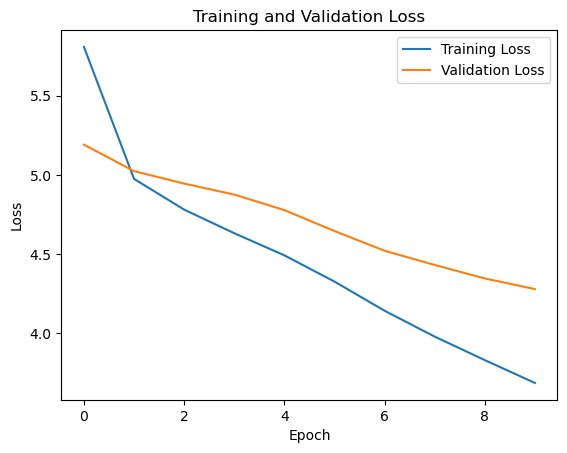

In [22]:
# 14. Training graph
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In this task, we used an Encoder-Decoder LSTM model to translate English sentences into French using the provided Kaggle dataset. We prepared the data using tokenization and padding, then trained the model for 10 epochs. The model achieved a test accuracy of 28.06%. However, some translations were incorrect, which shows that the model still needs improvement to produce more accurate translations.